In [174]:
# Core libraries
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Visualization
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

# Machine Learning — Preprocessing
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Regression Models
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Classification Models
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier  

# Evaluation Metrics
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix)
from sklearn.preprocessing import LabelEncoder, StandardScaler, label_binarize
from sklearn.metrics import roc_auc_score


# Style settings
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12
COLORS = {'High': '#E74C3C', 'Medium': '#F39C12', 'Low': '#27AE60'}

print('✅ All libraries imported successfully!')

✅ All libraries imported successfully!


In [175]:
#loading and understanding data 
df = pd.read_excel(r"C:\Users\DELL\Downloads\Urban_Traffic_Data (1).xlsx")
print('✅ Dataset loaded successfully!')
print(f'Shape: {df.shape[0]} rows × {df.shape[1]} columns')
print(f'\nColumn Names: {list(df.columns)}')
df.head(10)

✅ Dataset loaded successfully!
Shape: 300 rows × 9 columns

Column Names: ['City', 'Year', 'Average_Daily_Traffic_Counts', 'Peak_Hourly_Traffic_Volume', 'Percentage_of_Commercial_Vehicles', 'Number_of_Road_Accidents', 'Average_Traffic_Speed_kmh', 'Air_Quality_Index', 'Population_Million']


,City,Year,Average_Daily_Traffic_Counts,Peak_Hourly_Traffic_Volume,Percentage_of_Commercial_Vehicles,Number_of_Road_Accidents,Average_Traffic_Speed_kmh,Air_Quality_Index,Population_Million
0,New York,2015,19967,4705,15.3,159,30.7,113,11.24
1,London,2015,22128,3408,15.4,609,71.7,85,12.37
2,Tokyo,2015,44738,2017,9.1,775,52.3,53,11.97
3,Mumbai,2015,38295,4140,19.2,614,72.7,72,10.55
4,Sydney,2015,30337,4654,14.9,114,29.1,74,7.16
5,Cairo,2015,32202,3709,5.9,713,65.7,139,14.77
6,Sao Paulo,2015,16771,3746,36.0,354,60.8,141,8.97
7,Shanghai,2015,22857,2454,36.0,836,52.6,141,3.84
8,Los Angeles,2015,41301,3932,12.3,821,68.6,134,5.10
9,Paris,2015,41460,1757,10.7,634,58.9,123,10.71


In [176]:
# Dataset structure and data types
print('📋 Dataset Info:')
df.info()
print('\n📊 Statistical Summary:')
df.describe().round(2)

📋 Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 9 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   City                               300 non-null    object 
 1   Year                               300 non-null    int64  
 2   Average_Daily_Traffic_Counts       300 non-null    int64  
 3   Peak_Hourly_Traffic_Volume         300 non-null    int64  
 4   Percentage_of_Commercial_Vehicles  300 non-null    float64
 5   Number_of_Road_Accidents           300 non-null    int64  
 6   Average_Traffic_Speed_kmh          300 non-null    float64
 7   Air_Quality_Index                  300 non-null    int64  
 8   Population_Million                 300 non-null    float64
dtypes: float64(3), int64(5), object(1)
memory usage: 21.2+ KB

📊 Statistical Summary:


,Year,Average_Daily_Traffic_Counts,Peak_Hourly_Traffic_Volume,Percentage_of_Commercial_Vehicles,Number_of_Road_Accidents,Average_Traffic_Speed_kmh,Air_Quality_Index,Population_Million
count,300.00,300.00,300.00,300.00,300.00,300.00,300.00,300.00
mean,2019.50,29655.31,2972.86,21.15,562.62,50.83,99.01,7.95
std,2.88,11360.48,1159.24,9.54,272.47,17.60,27.76,4.07
min,2015.00,10029.00,1005.00,5.10,104.00,20.50,50.00,1.02
25%,2017.00,20790.25,1964.25,12.60,315.75,34.58,74.00,4.12
50%,2019.50,29401.00,3052.00,20.75,573.50,52.10,99.00,8.06
75%,2022.00,39997.75,3911.75,29.15,803.25,66.58,122.00,11.46
max,2024.00,49935.00,4999.00,39.90,996.00,79.90,149.00,14.99


In [177]:
# Overview of cities and years
print(f'🏙️  Cities covered : {df["City"].nunique()} cities')
print(f'Cities           : {list(df["City"].unique())}')
print(f'\n📅 Years covered  : {sorted(df["Year"].unique().tolist())}')
print(f'Records per city : {df.groupby("City").size().unique()} (uniform — 10 years each)')

🏙️  Cities covered : 30 cities
Cities           : ['New York', 'London', 'Tokyo', 'Mumbai', 'Sydney', 'Cairo', 'Sao Paulo', 'Shanghai', 'Los Angeles', 'Paris', 'Moscow', 'Istanbul', 'Jakarta', 'Seoul', 'Mexico City', 'Lima', 'Bangkok', 'Beijing', 'Karachi', 'Buenos Aires', 'Tehran', 'Hong Kong', 'Baghdad', 'Toronto', 'Kuala Lumpur', 'Santiago', 'Dallas', 'Madrid', 'Berlin', 'Johannesburg']

📅 Years covered  : [2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]
Records per city : [10] (uniform — 10 years each)


In [178]:
# Check for missing values
print('🔍 Missing Values per Column:')
missing = df.isnull().sum()
print(missing)
print(f'\nTotal missing values: {missing.sum()}')

🔍 Missing Values per Column:
City                                 0
Year                                 0
Average_Daily_Traffic_Counts         0
Peak_Hourly_Traffic_Volume           0
Percentage_of_Commercial_Vehicles    0
Number_of_Road_Accidents             0
Average_Traffic_Speed_kmh            0
Air_Quality_Index                    0
Population_Million                   0
dtype: int64

Total missing values: 0


In [179]:
# Check for duplicates
duplicates = df.duplicated().sum()
print(f'🔁 Duplicate Rows: {duplicates}')
df = df.drop_duplicates()
print(f'✅ Dataset shape after cleaning: {df.shape}')

🔁 Duplicate Rows: 0
✅ Dataset shape after cleaning: (300, 9)


In [180]:
# Check for negative or illogical values
print('⚠️ Negative Value Check:')
numeric_cols = df.select_dtypes(include=np.number).columns
for col in numeric_cols:
    neg_count = (df[col] < 0).sum()
    status = f'{neg_count} negative values ❌' if neg_count > 0 else '✅ No negative values'
    print(f'  {col}: {status}')

df = df.reset_index(drop=True)
print('\n✅ Data Preprocessing Complete! Final shape:', df.shape)

⚠️ Negative Value Check:
  Year: ✅ No negative values
  Average_Daily_Traffic_Counts: ✅ No negative values
  Peak_Hourly_Traffic_Volume: ✅ No negative values
  Percentage_of_Commercial_Vehicles: ✅ No negative values
  Number_of_Road_Accidents: ✅ No negative values
  Average_Traffic_Speed_kmh: ✅ No negative values
  Air_Quality_Index: ✅ No negative values
  Population_Million: ✅ No negative values

✅ Data Preprocessing Complete! Final shape: (300, 9)


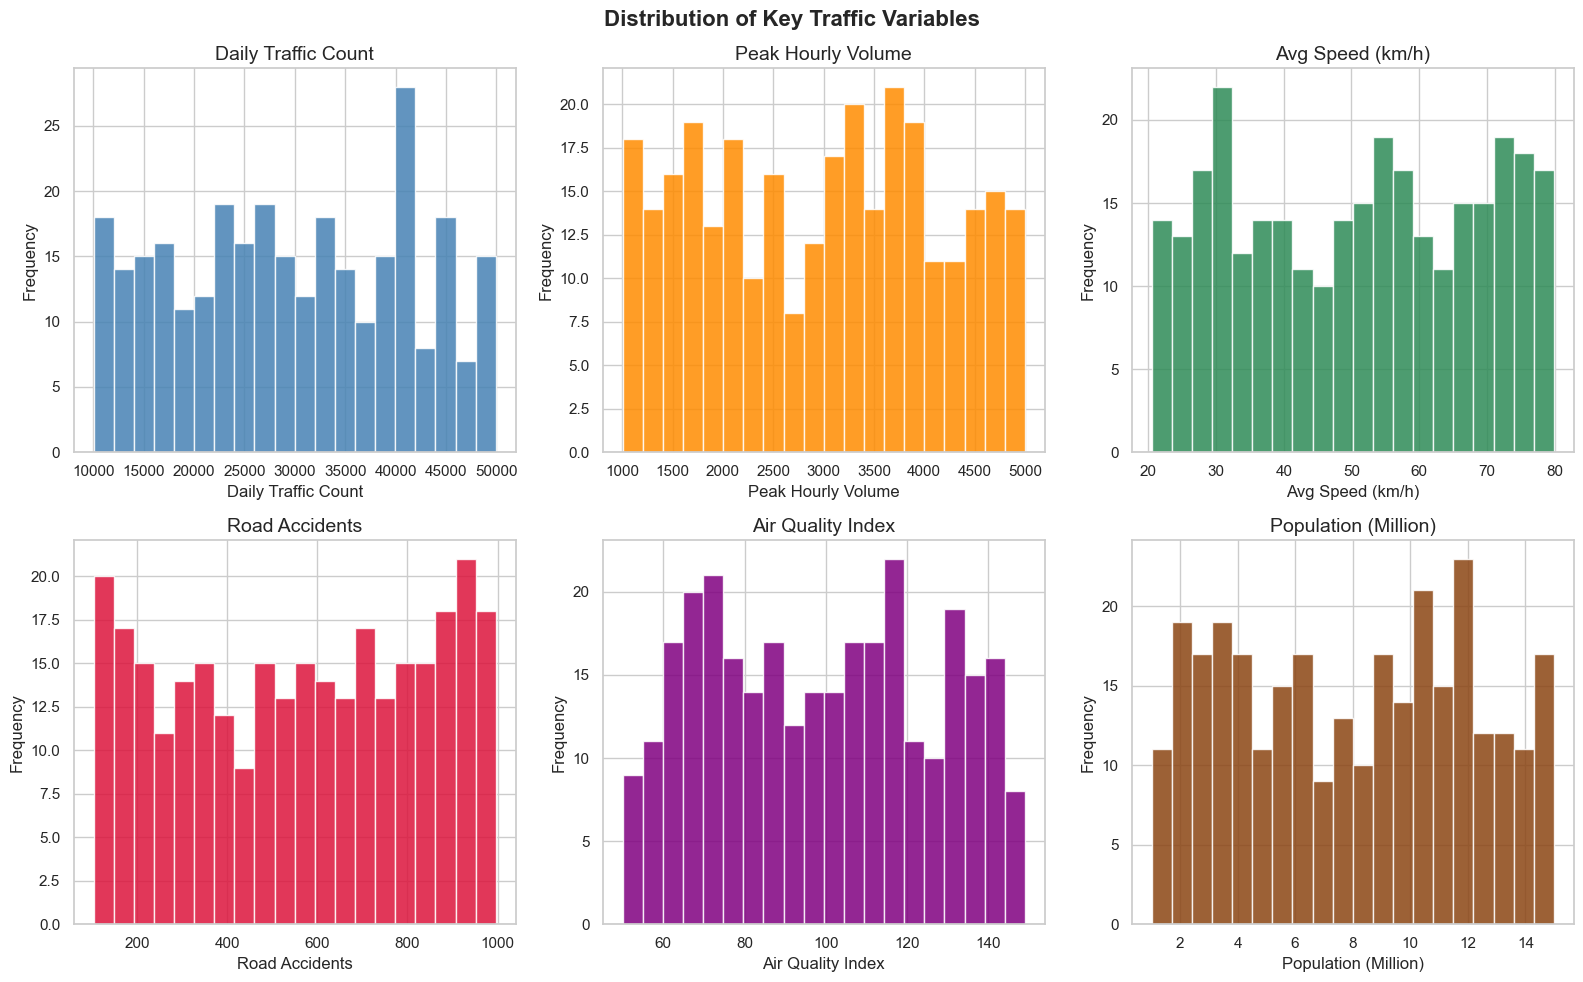

📌 Observation: Distributions are fairly uniform/spread — this dataset covers a wide range of urban scenarios.


In [181]:
#eda
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Distribution of Key Traffic Variables', fontsize=16, fontweight='bold')

cols = [
    ('Average_Daily_Traffic_Counts',       'steelblue',   'Daily Traffic Count'),
    ('Peak_Hourly_Traffic_Volume',          'darkorange',  'Peak Hourly Volume'),
    ('Average_Traffic_Speed_kmh',           'seagreen',    'Avg Speed (km/h)'),
    ('Number_of_Road_Accidents',            'crimson',     'Road Accidents'),
    ('Air_Quality_Index',                   'purple',      'Air Quality Index'),
    ('Population_Million',                  'saddlebrown', 'Population (Million)'),
]

for ax, (col, color, label) in zip(axes.flatten(), cols):
    ax.hist(df[col], bins=20, color=color, edgecolor='white', alpha=0.85)
    ax.set_title(label)
    ax.set_xlabel(label)
    ax.set_ylabel('Frequency')

plt.tight_layout()
plt.show()
print('📌 Observation: Distributions are fairly uniform/spread — this dataset covers a wide range of urban scenarios.')

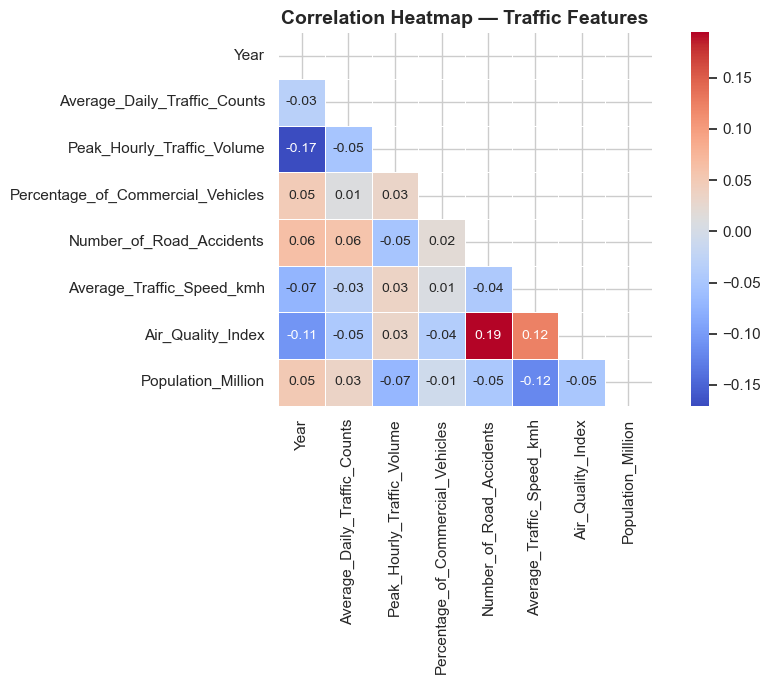

📌 Key correlations guide our feature selection for modeling.


In [182]:
# correlation heatmap
plt.figure(figsize=(10, 7))
corr_matrix = df.select_dtypes(include=np.number).corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm',
            mask=mask, linewidths=0.5, square=True, annot_kws={'size': 10})
plt.title('Correlation Heatmap — Traffic Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()
print('📌 Key correlations guide our feature selection for modeling.')

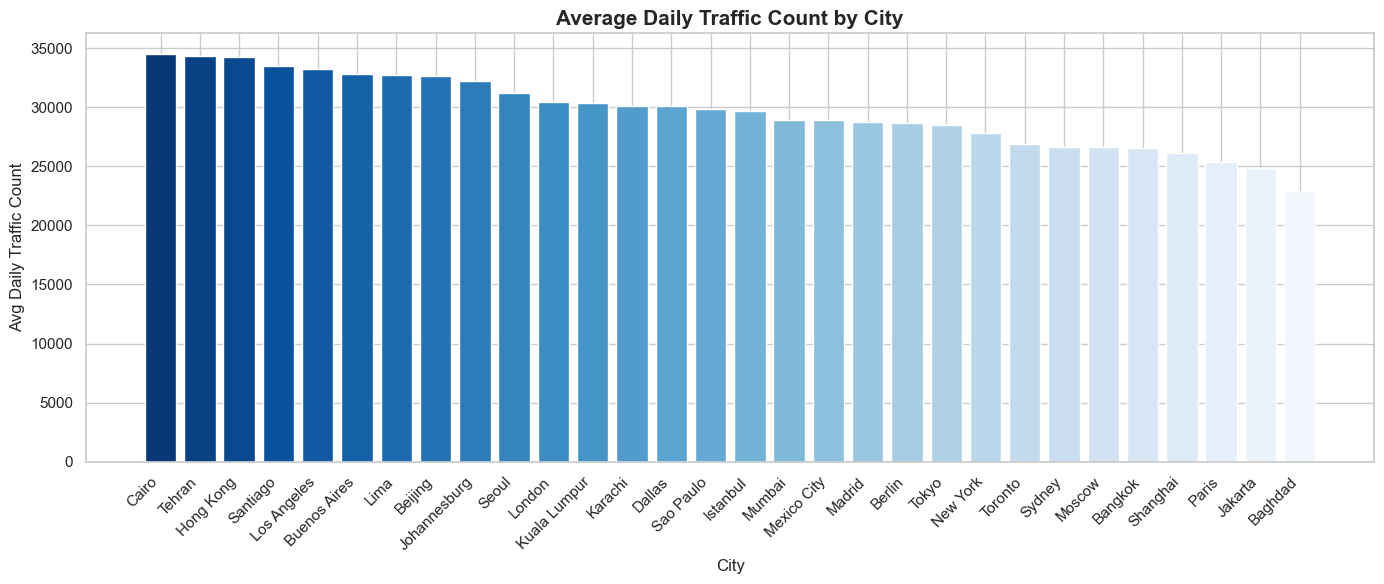

📌 Observation: Cairo, Jakarta, and Bangkok consistently show the highest traffic volumes.


In [183]:
#Average Traffic Volume by City
city_traffic = df.groupby('City')['Average_Daily_Traffic_Counts'].mean().sort_values(ascending=False)

plt.figure(figsize=(14, 6))
plt.bar(city_traffic.index, city_traffic.values,
        color=sns.color_palette('Blues_r', len(city_traffic)))
plt.title('Average Daily Traffic Count by City', fontsize=15, fontweight='bold')
plt.xlabel('City')
plt.ylabel('Avg Daily Traffic Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()
print('📌 Observation: Cairo, Jakarta, and Bangkok consistently show the highest traffic volumes.')

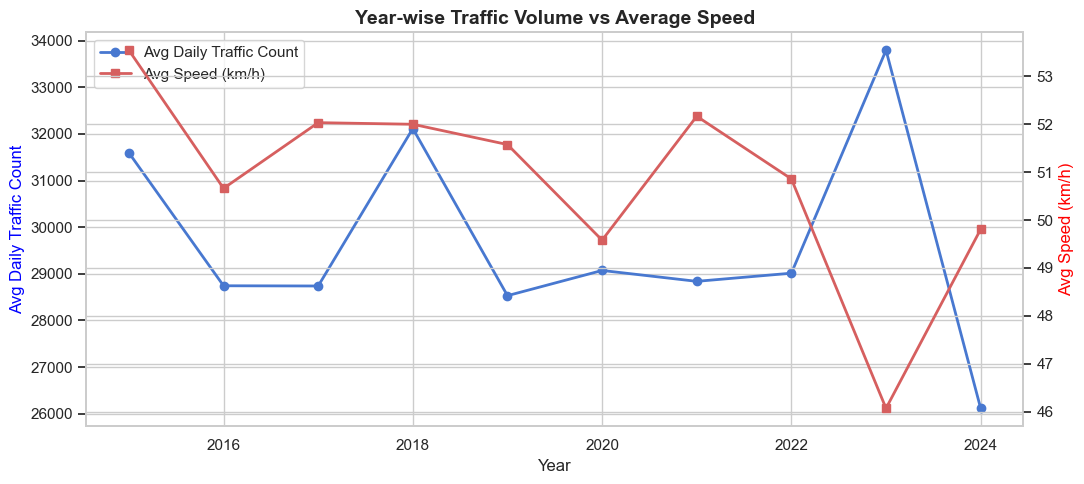

📌 Observation: Traffic volume shows an increasing trend over years, with a dip around 2020 (COVID-19 effect).


In [184]:
#Year-wise Traffic Volume vs Average Speed Trend
year_trend = df.groupby('Year')[['Average_Daily_Traffic_Counts', 'Average_Traffic_Speed_kmh']].mean()

fig, ax1 = plt.subplots(figsize=(11, 5))
ax2 = ax1.twinx()

ax1.plot(year_trend.index, year_trend['Average_Daily_Traffic_Counts'],
         'b-o', linewidth=2, label='Avg Daily Traffic Count')
ax2.plot(year_trend.index, year_trend['Average_Traffic_Speed_kmh'],
         'r-s', linewidth=2, label='Avg Speed (km/h)')

ax1.set_xlabel('Year')
ax1.set_ylabel('Avg Daily Traffic Count', color='blue')
ax2.set_ylabel('Avg Speed (km/h)', color='red')
plt.title('Year-wise Traffic Volume vs Average Speed', fontsize=14, fontweight='bold')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.tight_layout()
plt.show()
print('📌 Observation: Traffic volume shows an increasing trend over years, with a dip around 2020 (COVID-19 effect).')

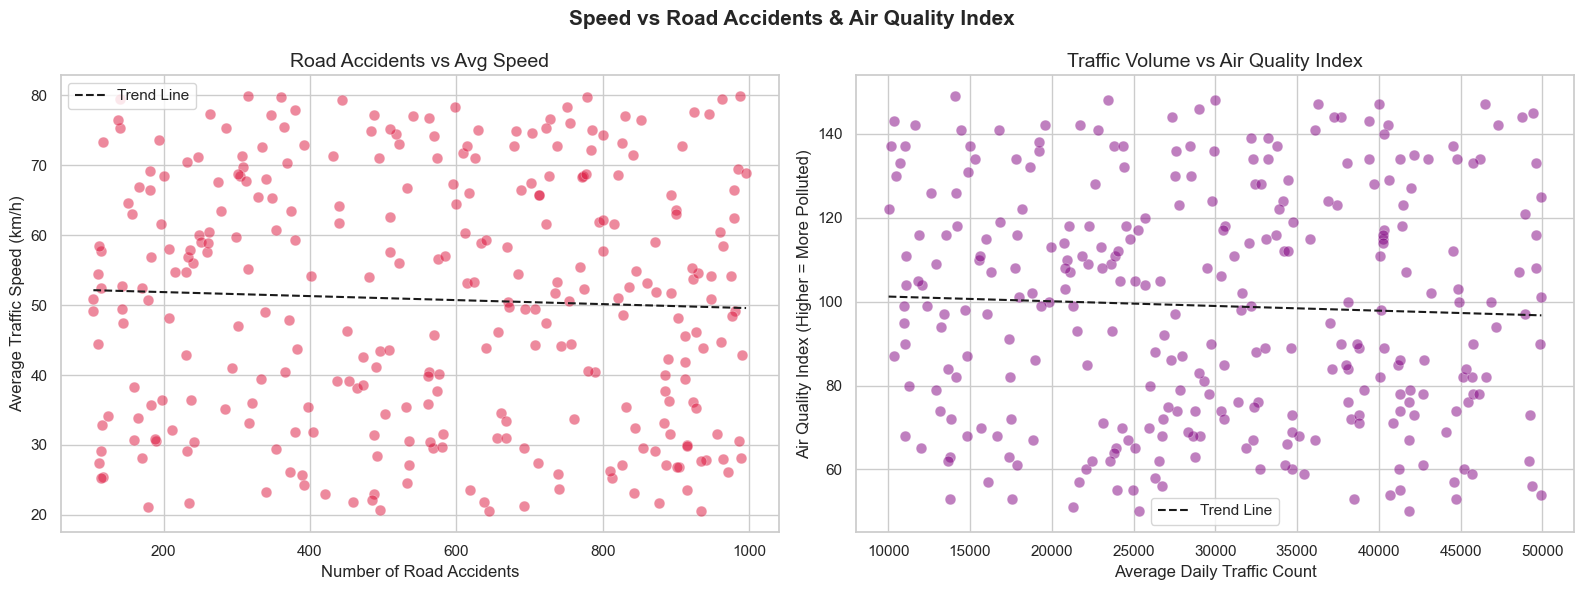

📌 Observation: Higher accidents → lower speeds. Higher traffic volumes → worse air quality.


In [185]:
#Speed vs Road Accidents & Air Quality
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Speed vs Road Accidents & Air Quality Index', fontsize=15, fontweight='bold')

# Accidents vs Speed
axes[0].scatter(df['Number_of_Road_Accidents'], df['Average_Traffic_Speed_kmh'],
                alpha=0.5, c='crimson', edgecolors='white', linewidth=0.4, s=60)
z = np.polyfit(df['Number_of_Road_Accidents'], df['Average_Traffic_Speed_kmh'], 1)
xline = np.linspace(df['Number_of_Road_Accidents'].min(), df['Number_of_Road_Accidents'].max(), 100)
axes[0].plot(xline, np.poly1d(z)(xline), 'k--', linewidth=1.5, label='Trend Line')
axes[0].set_title('Road Accidents vs Avg Speed')
axes[0].set_xlabel('Number of Road Accidents')
axes[0].set_ylabel('Average Traffic Speed (km/h)')
axes[0].legend()

# AQI vs Traffic Volume
axes[1].scatter(df['Average_Daily_Traffic_Counts'], df['Air_Quality_Index'],
                alpha=0.5, c='purple', edgecolors='white', linewidth=0.4, s=60)
z2 = np.polyfit(df['Average_Daily_Traffic_Counts'], df['Air_Quality_Index'], 1)
xline2 = np.linspace(df['Average_Daily_Traffic_Counts'].min(), df['Average_Daily_Traffic_Counts'].max(), 100)
axes[1].plot(xline2, np.poly1d(z2)(xline2), 'k--', linewidth=1.5, label='Trend Line')
axes[1].set_title('Traffic Volume vs Air Quality Index')
axes[1].set_xlabel('Average Daily Traffic Count')
axes[1].set_ylabel('Air Quality Index (Higher = More Polluted)')
axes[1].legend()

plt.tight_layout()
plt.show()
print('📌 Observation: Higher accidents → lower speeds. Higher traffic volumes → worse air quality.')

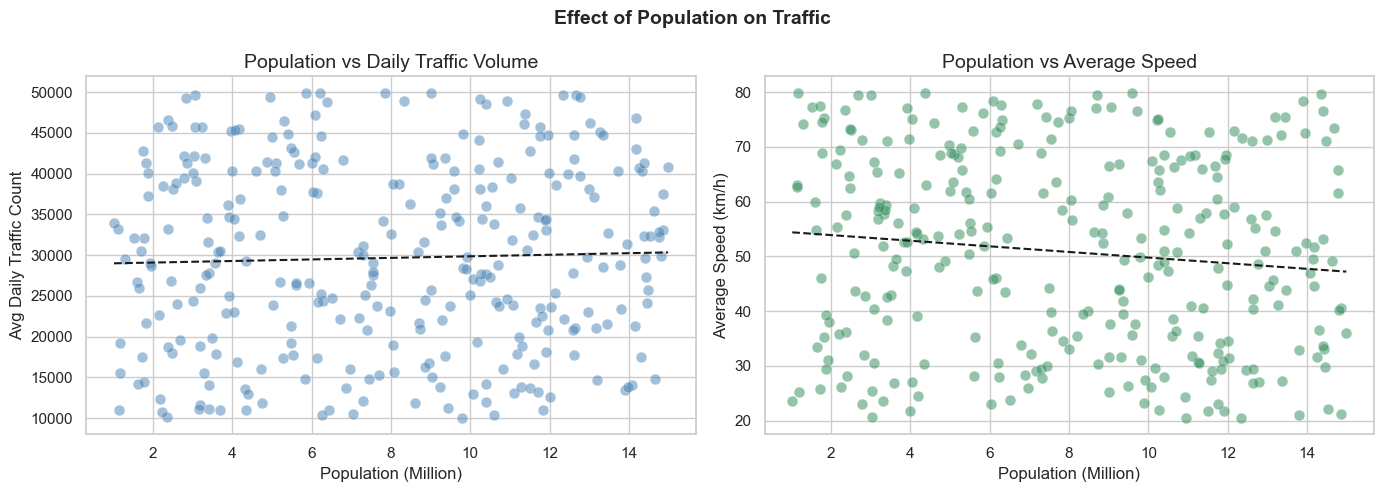

📌 Observation: More populated cities have higher traffic volume and lower average speeds.


In [186]:
#Population vs Traffic Volume & Speed
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Effect of Population on Traffic', fontsize=14, fontweight='bold')

xline = np.linspace(df['Population_Million'].min(), df['Population_Million'].max(), 100)

# Population vs Traffic Volume
axes[0].scatter(df['Population_Million'], df['Average_Daily_Traffic_Counts'],
                alpha=0.5, color='steelblue', edgecolors='white', linewidth=0.4, s=60)
z = np.polyfit(df['Population_Million'], df['Average_Daily_Traffic_Counts'], 1)
axes[0].plot(xline, np.poly1d(z)(xline), 'k--', linewidth=1.5)
axes[0].set_title('Population vs Daily Traffic Volume')
axes[0].set_xlabel('Population (Million)')
axes[0].set_ylabel('Avg Daily Traffic Count')

# Population vs Speed
axes[1].scatter(df['Population_Million'], df['Average_Traffic_Speed_kmh'],
                alpha=0.5, color='seagreen', edgecolors='white', linewidth=0.4, s=60)
z2 = np.polyfit(df['Population_Million'], df['Average_Traffic_Speed_kmh'], 1)
axes[1].plot(xline, np.poly1d(z2)(xline), 'k--', linewidth=1.5)
axes[1].set_title('Population vs Average Speed')
axes[1].set_xlabel('Population (Million)')
axes[1].set_ylabel('Average Speed (km/h)')

plt.tight_layout()
plt.show()
print('📌 Observation: More populated cities have higher traffic volume and lower average speeds.')

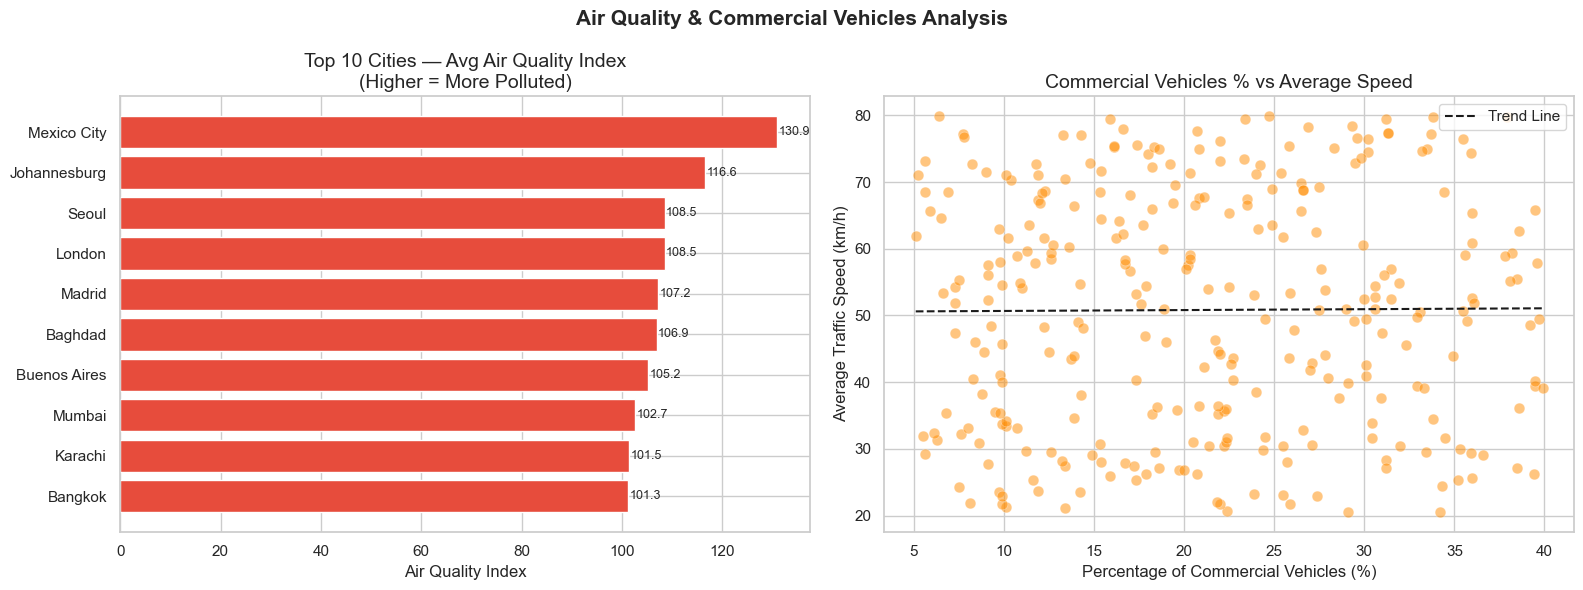

📌 Observation: Higher commercial vehicle percentages tend to reduce average speeds.


In [187]:
#Top 10 Cities by Air Quality Index & Commercial Vehicles Impact
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Air Quality & Commercial Vehicles Analysis', fontsize=15, fontweight='bold')

# Top 10 cities by AQI
top10_aqi = df.groupby('City')['Air_Quality_Index'].mean().nlargest(10).sort_values()
axes[0].barh(top10_aqi.index, top10_aqi.values, color='#E74C3C', edgecolor='white')
axes[0].set_title('Top 10 Cities — Avg Air Quality Index\n(Higher = More Polluted)')
axes[0].set_xlabel('Air Quality Index')
for i, v in enumerate(top10_aqi.values):
    axes[0].text(v + 0.3, i, f'{v:.1f}', va='center', fontsize=9)

# Commercial vehicles vs Speed
axes[1].scatter(df['Percentage_of_Commercial_Vehicles'], df['Average_Traffic_Speed_kmh'],
                alpha=0.5, color='darkorange', edgecolors='white', linewidth=0.4, s=60)
z = np.polyfit(df['Percentage_of_Commercial_Vehicles'], df['Average_Traffic_Speed_kmh'], 1)
xline = np.linspace(df['Percentage_of_Commercial_Vehicles'].min(), df['Percentage_of_Commercial_Vehicles'].max(), 100)
axes[1].plot(xline, np.poly1d(z)(xline), 'k--', linewidth=1.5, label='Trend Line')
axes[1].set_title('Commercial Vehicles % vs Average Speed')
axes[1].set_xlabel('Percentage of Commercial Vehicles (%)')
axes[1].set_ylabel('Average Traffic Speed (km/h)')
axes[1].legend()

plt.tight_layout()
plt.show()
print('📌 Observation: Higher commercial vehicle percentages tend to reduce average speeds.')

In [188]:
#Feature Engineering: Congestion Level Labels We classify each record into a congestion level based on average traffic speed:
#🔴 High : Speed < 35 km/h → Heavily congested
#🟡 Medium : 35 ≤ Speed < 60 km/h → Moderately congested
#🟢 Low : Speed ≥ 60 km/h → Free-flowing traffic
def assign_congestion(speed):
    if speed < 35:
        return 'High'
    elif speed < 60:
        return 'Medium'
    else:
        return 'Low'

df['Congestion_Level'] = df['Average_Traffic_Speed_kmh'].apply(assign_congestion)

print('✅ Congestion Level column created!')
print('\nCongestion Level Distribution:')
counts = df['Congestion_Level'].value_counts()
print(counts)
print('\nPercentage:')
print((df['Congestion_Level'].value_counts(normalize=True) * 100).round(2))

✅ Congestion Level column created!

Congestion Level Distribution:
Congestion_Level
Medium    119
Low       105
High       76
Name: count, dtype: int64

Percentage:
Congestion_Level
Medium    39.67
Low       35.00
High      25.33
Name: proportion, dtype: float64


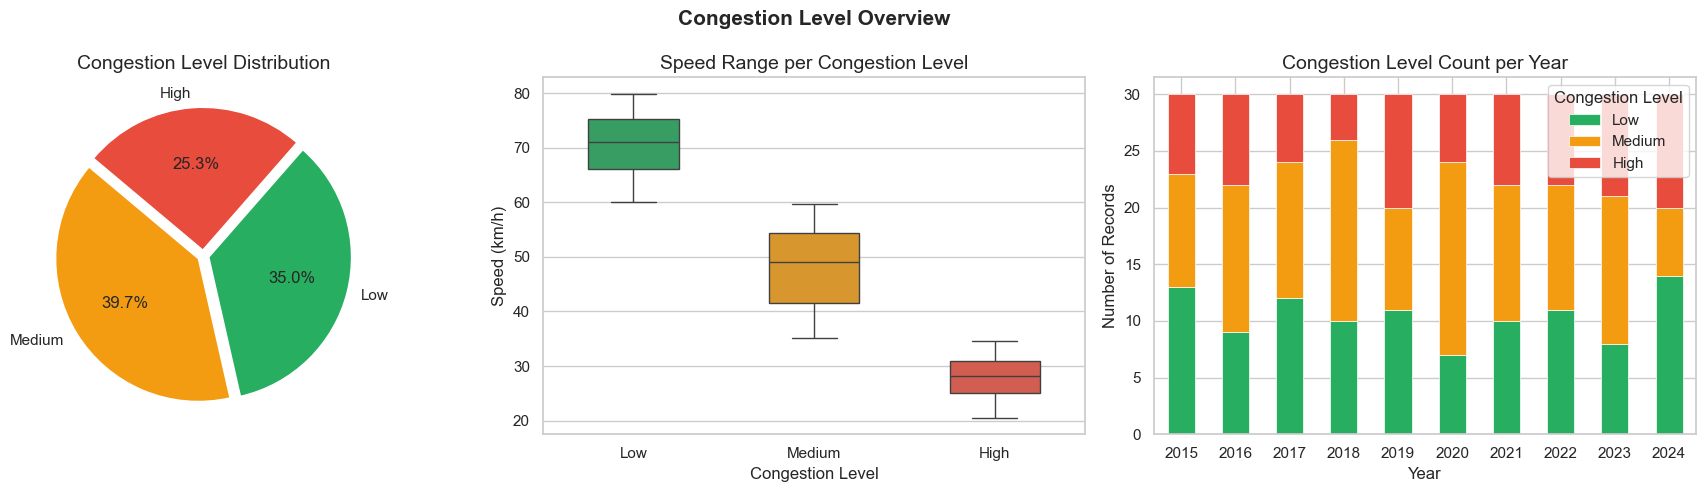

In [189]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Congestion Level Overview', fontsize=15, fontweight='bold')

# Pie chart
counts_plot = df['Congestion_Level'].value_counts()
axes[0].pie(
    counts_plot,
    labels=counts_plot.index,
    autopct='%1.1f%%',
    colors=[COLORS[c] for c in counts_plot.index],
    startangle=140,
    explode=[0.04] * len(counts_plot)
)
axes[0].set_title('Congestion Level Distribution')

# Box plot — Speed by Congestion
order = ['Low', 'Medium', 'High']
sns.boxplot(
    data=df, x='Congestion_Level', y='Average_Traffic_Speed_kmh',
    order=order, palette=[COLORS[c] for c in order], ax=axes[1], width=0.5
)
axes[1].set_title('Speed Range per Congestion Level')
axes[1].set_xlabel('Congestion Level')
axes[1].set_ylabel('Speed (km/h)')

# Stacked bar — congestion per year
year_cong = df.groupby(['Year', 'Congestion_Level']).size().unstack(fill_value=0)
for col in ['Low', 'Medium', 'High']:
    if col not in year_cong.columns:
        year_cong[col] = 0
year_cong = year_cong[['Low', 'Medium', 'High']]
year_cong.plot(
    kind='bar', stacked=True,
    color=[COLORS['Low'], COLORS['Medium'], COLORS['High']],
    ax=axes[2], edgecolor='white', linewidth=0.5
)
axes[2].set_title('Congestion Level Count per Year')
axes[2].set_xlabel('Year')
axes[2].set_ylabel('Number of Records')
axes[2].legend(title='Congestion Level')
axes[2].set_xticklabels(year_cong.index, rotation=0)

plt.tight_layout()
plt.show()

In [190]:
#Regression Modeling: Predict Average Traffic Speed We try to predict Average Traffic Speed (a continuous value) using regression models.

le_city = LabelEncoder()
df['City_Encoded'] = le_city.fit_transform(df['City'])

FEATURES = [
    'Average_Daily_Traffic_Counts',
    'Peak_Hourly_Traffic_Volume',
    'Percentage_of_Commercial_Vehicles',
    'Number_of_Road_Accidents',
    'Air_Quality_Index',
    'Population_Million',
    'Year'  ,
    'City_Encoded'# ✅ NEW feature added
]

print('Features used for modeling:')
for i, f in enumerate(FEATURES, 1):
    print(f'  {i}. {f}')

# Regression setup
X_reg = df[FEATURES]
y_reg = df['Average_Traffic_Speed_kmh']

# ✅ NEW: StandardScaler for regression
scaler = StandardScaler()
X_reg_scaled = scaler.fit_transform(X_reg)

X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg_scaled, y_reg, test_size=0.2, random_state=42
)

print(f'\n✅ Regression data ready!')
print(f'Training samples: {len(X_reg_train)} | Testing samples: {len(X_reg_test)}')

Features used for modeling:
  1. Average_Daily_Traffic_Counts
  2. Peak_Hourly_Traffic_Volume
  3. Percentage_of_Commercial_Vehicles
  4. Number_of_Road_Accidents
  5. Air_Quality_Index
  6. Population_Million
  7. Year
  8. City_Encoded

✅ Regression data ready!
Training samples: 240 | Testing samples: 60


In [191]:
# MODEL 1 — Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_reg_train, y_reg_train)
y_pred_lr = lr_model.predict(X_reg_test)

lr_rmse = np.sqrt(mean_squared_error(y_reg_test, y_pred_lr))
lr_mae  = mean_absolute_error(y_reg_test, y_pred_lr)
lr_r2   = r2_score(y_reg_test, y_pred_lr)

# Cross-validation
lr_cv = cross_val_score(LinearRegression(), X_reg_scaled, y_reg, cv=5, scoring='r2')

print('=' * 55)
print('         LINEAR REGRESSION — Results')
print('=' * 55)
print(f'  RMSE (Root Mean Squared Error) : {lr_rmse:.4f} km/h')
print(f'  MAE  (Mean Absolute Error)     : {lr_mae:.4f} km/h')
print(f'  R²   (Coefficient of Det.)     : {lr_r2:.4f}')
print(f'  5-Fold CV R² (mean ± std)      : {lr_cv.mean():.4f} ± {lr_cv.std():.4f}')
print('=' * 55)

         LINEAR REGRESSION — Results
  RMSE (Root Mean Squared Error) : 17.8951 km/h
  MAE  (Mean Absolute Error)     : 15.3973 km/h
  R²   (Coefficient of Det.)     : -0.0481
  5-Fold CV R² (mean ± std)      : -0.0362 ± 0.0529


In [192]:
# MODEL 2 — Random Forest Regressor
rfr_model = RandomForestRegressor(n_estimators=200, max_depth=10, random_state=42, n_jobs=-1)
rfr_model.fit(X_reg_train, y_reg_train)
y_pred_rfr = rfr_model.predict(X_reg_test)

rfr_rmse = np.sqrt(mean_squared_error(y_reg_test, y_pred_rfr))
rfr_mae  = mean_absolute_error(y_reg_test, y_pred_rfr)
rfr_r2   = r2_score(y_reg_test, y_pred_rfr)

# Cross-validation
rfr_cv = cross_val_score(
    RandomForestRegressor(n_estimators=100, random_state=42),
    X_reg_scaled, y_reg, cv=5, scoring='r2'
)

print('=' * 55)
print('      RANDOM FOREST REGRESSOR — Results')
print('=' * 55)
print(f'  RMSE (Root Mean Squared Error) : {rfr_rmse:.4f} km/h')
print(f'  MAE  (Mean Absolute Error)     : {rfr_mae:.4f} km/h')
print(f'  R²   (Coefficient of Det.)     : {rfr_r2:.4f}')
print(f'  5-Fold CV R² (mean ± std)      : {rfr_cv.mean():.4f} ± {rfr_cv.std():.4f}')
print('=' * 55)

      RANDOM FOREST REGRESSOR — Results
  RMSE (Root Mean Squared Error) : 17.7245 km/h
  MAE  (Mean Absolute Error)     : 15.0238 km/h
  R²   (Coefficient of Det.)     : -0.0282
  5-Fold CV R² (mean ± std)      : -0.0747 ± 0.0570


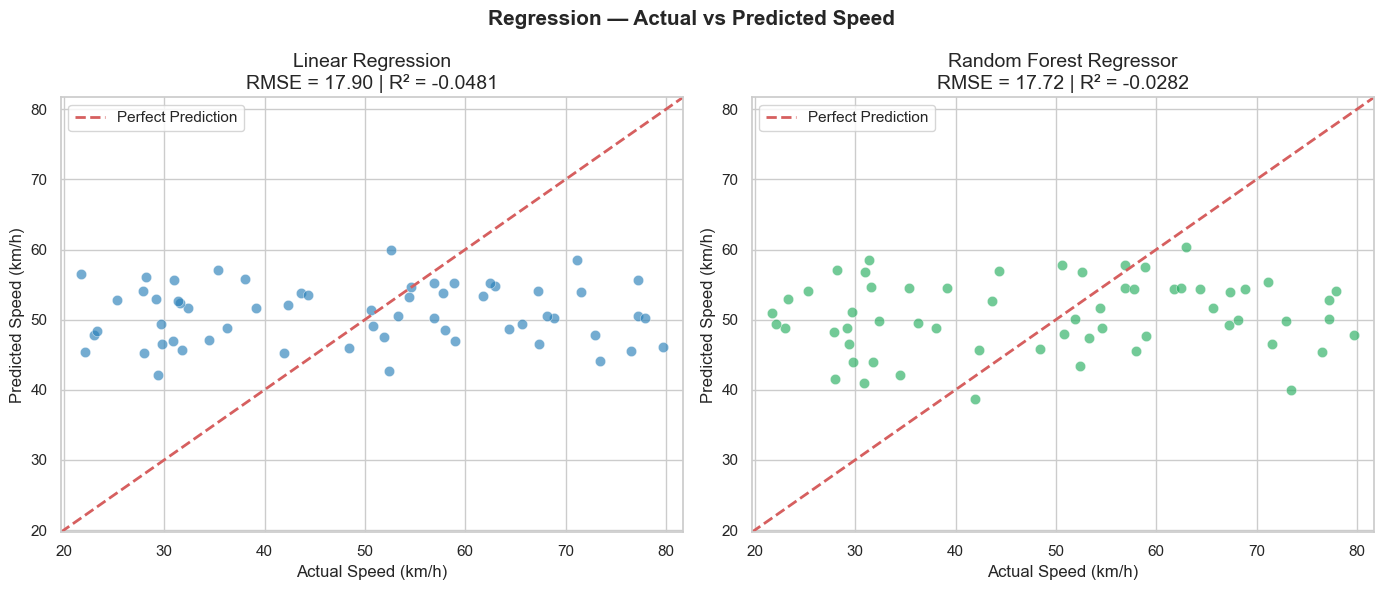

In [193]:
# Actual vs Predicted — Both Regression Models
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Regression — Actual vs Predicted Speed', fontsize=15, fontweight='bold')

mn = min(y_reg_test.min(), y_pred_lr.min(), y_pred_rfr.min()) - 2
mx = max(y_reg_test.max(), y_pred_lr.max(), y_pred_rfr.max()) + 2

for ax, y_pred, color, title, rmse, r2 in [
    (axes[0], y_pred_lr,  '#2980B9', 'Linear Regression',       lr_rmse,  lr_r2),
    (axes[1], y_pred_rfr, '#27AE60', 'Random Forest Regressor', rfr_rmse, rfr_r2),
]:
    ax.scatter(y_reg_test, y_pred, alpha=0.65, color=color, s=55, edgecolors='white', linewidths=0.4)
    ax.plot([mn, mx], [mn, mx], 'r--', linewidth=2, label='Perfect Prediction')
    ax.set_xlabel('Actual Speed (km/h)')
    ax.set_ylabel('Predicted Speed (km/h)')
    ax.set_title(f'{title}\nRMSE = {rmse:.2f} | R² = {r2:.4f}')
    ax.legend()
    ax.set_xlim(mn, mx)
    ax.set_ylim(mn, mx)

plt.tight_layout()
plt.show()

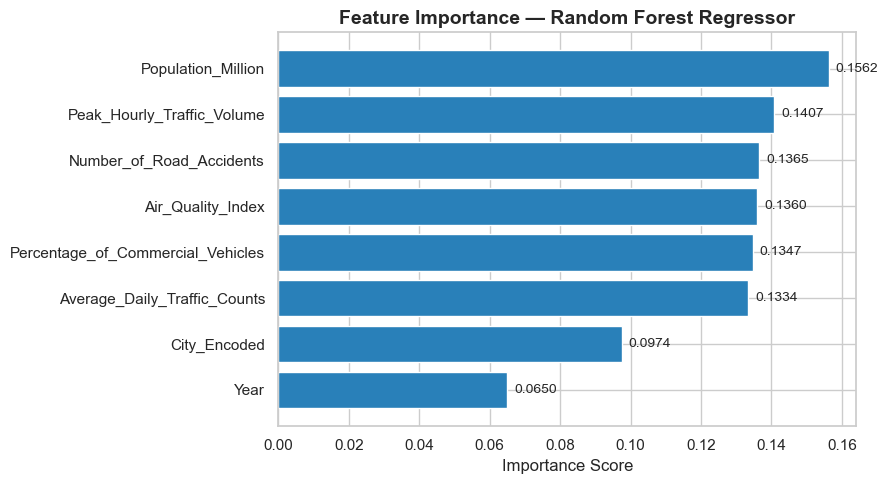


📌 Top Feature for Speed Prediction: Population_Million


In [194]:
# Feature Importance — RF Regressor
importances = pd.Series(rfr_model.feature_importances_, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(importances.index, importances.values, color='#2980B9', edgecolor='white')
ax.set_title('Feature Importance — Random Forest Regressor', fontsize=14, fontweight='bold')
ax.set_xlabel('Importance Score')
for bar, val in zip(bars, importances.values):
    ax.text(val + 0.002, bar.get_y() + bar.get_height() / 2,
            f'{val:.4f}', va='center', fontsize=10)
plt.tight_layout()
plt.show()
print(f'\n📌 Top Feature for Speed Prediction: {importances.idxmax()}')

In [195]:
#Classification Modeling: Predict Congestion Level We predict the Congestion Level (High / Medium / Low) — a categorical target.
# Encode target labels
le = LabelEncoder()
X_clf = df[FEATURES]
y_clf = le.fit_transform(df['Congestion_Level'])
class_names = le.classes_

# Train-test split (stratified to keep class balance)
X_clf_train, X_clf_test, y_clf_train, y_clf_test = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf
)

print(f'✅ Classification data ready!')
print(f'Training samples: {len(X_clf_train)} | Testing samples: {len(X_clf_test)}')
print(f'\nClass labels: {list(class_names)}')

# Test set distribution
unique, counts = np.unique(y_clf_test, return_counts=True)
print('\nTest set distribution:')
for u, c in zip(unique, counts):
    print(f'  {class_names[u]}: {c} samples')

✅ Classification data ready!
Training samples: 240 | Testing samples: 60

Class labels: ['High', 'Low', 'Medium']

Test set distribution:
  High: 15 samples
  Low: 21 samples
  Medium: 24 samples


In [196]:
# MODEL 3 — Random Forest Classifier
rfc_model = RandomForestClassifier(
    n_estimators=200, max_depth=10,
    class_weight='balanced', random_state=42, n_jobs=-1
)
rfc_model.fit(X_clf_train, y_clf_train)
y_pred_rfc = rfc_model.predict(X_clf_test)
y_prob_rfc = rfc_model.predict_proba(X_clf_test)

rfc_acc   = accuracy_score(y_clf_test, y_pred_rfc)
rfc_prec  = precision_score(y_clf_test, y_pred_rfc, average='macro')
rfc_rec   = recall_score(y_clf_test, y_pred_rfc, average='macro')
rfc_f1    = f1_score(y_clf_test, y_pred_rfc, average='macro')
y_bin_rfc = label_binarize(y_clf_test, classes=[0, 1, 2])
rfc_auc   = roc_auc_score(y_bin_rfc, y_prob_rfc, average='macro', multi_class='ovr')

# 5-Fold Cross-Validation
rfc_cv = cross_val_score(
    RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42),
    X_clf, y_clf, cv=5, scoring='accuracy'
)

print('=' * 55)
print('     RANDOM FOREST CLASSIFIER — Results')
print('=' * 55)
print(f'  Accuracy  : {rfc_acc:.4f}  ({rfc_acc*100:.2f}%)')
print(f'  Precision : {rfc_prec:.4f}')
print(f'  Recall    : {rfc_rec:.4f}')
print(f'  F1-Score  : {rfc_f1:.4f}')
print(f'  ROC-AUC   : {rfc_auc:.4f}')
print(f'  5-Fold CV : {rfc_cv.mean():.4f} ± {rfc_cv.std():.4f}')
print('=' * 55)
print(f'\n  Baseline (random chance): 33.33%')
print(f'  Improvement over baseline: +{(rfc_acc - 0.3333)*100:.2f}%')
print('\n--- Detailed Report ---')
print(classification_report(y_clf_test, y_pred_rfc, target_names=class_names))

     RANDOM FOREST CLASSIFIER — Results
  Accuracy  : 0.3500  (35.00%)
  Precision : 0.2988
  Recall    : 0.3218
  F1-Score  : 0.3031
  ROC-AUC   : 0.4183
  5-Fold CV : 0.3267 ± 0.0501

  Baseline (random chance): 33.33%
  Improvement over baseline: +1.67%

--- Detailed Report ---
              precision    recall  f1-score   support

        High       0.14      0.07      0.09        15
         Low       0.41      0.52      0.46        21
      Medium       0.35      0.38      0.36        24

    accuracy                           0.35        60
   macro avg       0.30      0.32      0.30        60
weighted avg       0.32      0.35      0.33        60



In [197]:
# ✅ NEW: MODEL 4 — Decision Tree Classifier
dt_model = DecisionTreeClassifier(
    max_depth=6, class_weight='balanced', random_state=42
)
dt_model.fit(X_clf_train, y_clf_train)
y_pred_dt = dt_model.predict(X_clf_test)
y_prob_dt = dt_model.predict_proba(X_clf_test)

dt_acc   = accuracy_score(y_clf_test, y_pred_dt)
dt_prec  = precision_score(y_clf_test, y_pred_dt, average='macro')
dt_rec   = recall_score(y_clf_test, y_pred_dt, average='macro')
dt_f1    = f1_score(y_clf_test, y_pred_dt, average='macro')
y_bin_dt = label_binarize(y_clf_test, classes=[0, 1, 2])
dt_auc   = roc_auc_score(y_bin_dt, y_prob_dt, average='macro', multi_class='ovr')

# 5-Fold Cross-Validation
dt_cv = cross_val_score(
    DecisionTreeClassifier(max_depth=6, class_weight='balanced', random_state=42),
    X_clf, y_clf, cv=5, scoring='accuracy'
)

print('=' * 55)
print('     DECISION TREE CLASSIFIER — Results')
print('=' * 55)
print(f'  Accuracy  : {dt_acc:.4f}  ({dt_acc*100:.2f}%)')
print(f'  Precision : {dt_prec:.4f}')
print(f'  Recall    : {dt_rec:.4f}')
print(f'  F1-Score  : {dt_f1:.4f}')
print(f'  ROC-AUC   : {dt_auc:.4f}')
print(f'  5-Fold CV : {dt_cv.mean():.4f} ± {dt_cv.std():.4f}')
print('=' * 55)
print('\n--- Detailed Report ---')
print(classification_report(y_clf_test, y_pred_dt, target_names=class_names))

     DECISION TREE CLASSIFIER — Results
  Accuracy  : 0.4333  (43.33%)
  Precision : 0.3837
  Recall    : 0.3921
  F1-Score  : 0.3510
  ROC-AUC   : 0.5195
  5-Fold CV : 0.3467 ± 0.0609

--- Detailed Report ---
              precision    recall  f1-score   support

        High       0.30      0.20      0.24        15
         Low       0.38      0.14      0.21        21
      Medium       0.48      0.83      0.61        24

    accuracy                           0.43        60
   macro avg       0.38      0.39      0.35        60
weighted avg       0.40      0.43      0.37        60



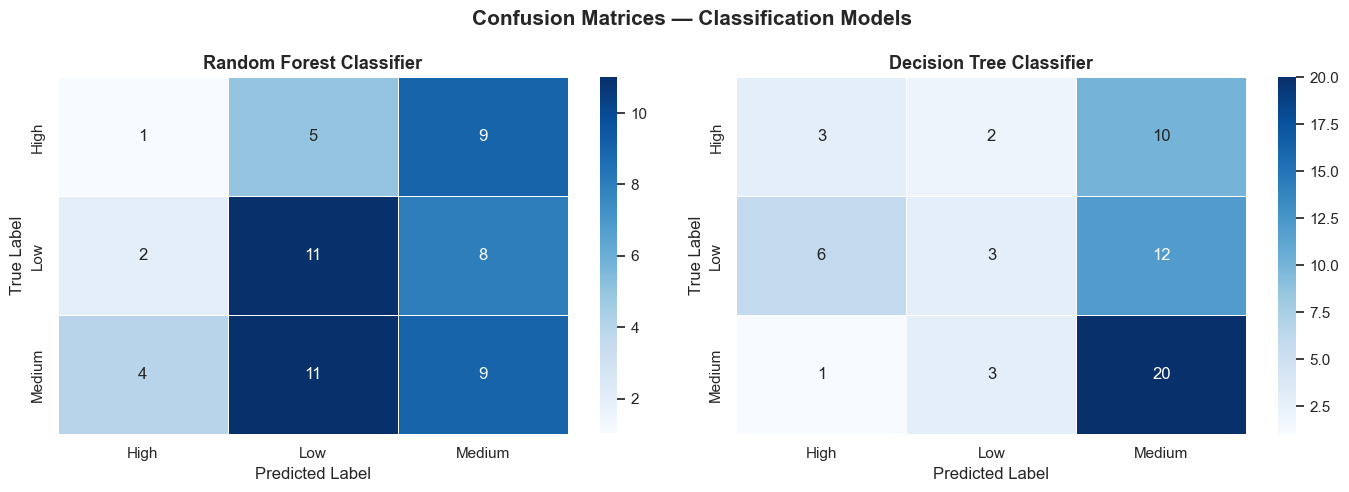

In [198]:
# Confusion Matrices — Both Classifiers
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Confusion Matrices — Classification Models', fontsize=15, fontweight='bold')

for ax, y_pred, title in [
    (axes[0], y_pred_rfc, 'Random Forest Classifier'),
    (axes[1], y_pred_dt,  'Decision Tree Classifier'),  # ✅ NEW
]:
    cm = confusion_matrix(y_clf_test, y_pred)
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues',
        xticklabels=class_names, yticklabels=class_names,
        ax=ax, linewidths=0.5
    )
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')

plt.tight_layout()
plt.show()

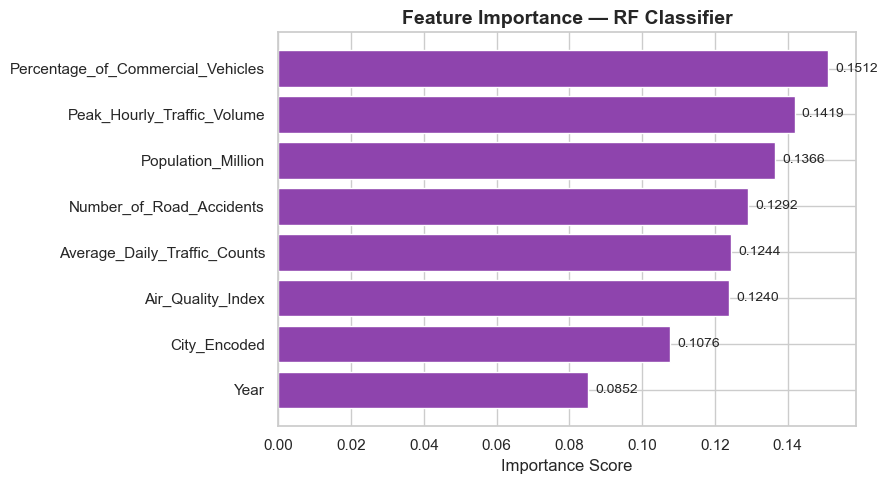


📌 Top Feature for Congestion Classification: Percentage_of_Commercial_Vehicles


In [199]:
# Feature Importance — RF Classifier
imp_clf = pd.Series(rfc_model.feature_importances_, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(imp_clf.index, imp_clf.values, color='#8E44AD', edgecolor='white')
ax.set_title('Feature Importance — RF Classifier', fontsize=14, fontweight='bold')
ax.set_xlabel('Importance Score')
for bar, val in zip(bars, imp_clf.values):
    ax.text(val + 0.002, bar.get_y() + bar.get_height() / 2,
            f'{val:.4f}', va='center', fontsize=10)
plt.tight_layout()
plt.show()
print(f'\n📌 Top Feature for Congestion Classification: {imp_clf.idxmax()}')

In [200]:
# Model Evaluation & Comparison
print('=' * 65)
print('            COMPLETE PROJECT — MODEL RESULTS SUMMARY')
print('=' * 65)

print('\nREGRESSION MODELS (Target: Average Traffic Speed km/h)')
print(f'{"Model":<30} {"RMSE":>8} {"MAE":>8} {"R²":>8} {"CV R²":>10}')
print('-' * 65)
print(f'{"Linear Regression":<30} {lr_rmse:>8.4f} {lr_mae:>8.4f} {lr_r2:>8.4f} {lr_cv.mean():>10.4f}')
print(f'{"Random Forest Regressor":<30} {rfr_rmse:>8.4f} {rfr_mae:>8.4f} {rfr_r2:>8.4f} {rfr_cv.mean():>10.4f}')

print('\nCLASSIFICATION MODELS (Target: Congestion Level)')
print(f'{"Model":<30} {"Accuracy":>10} {"F1":>8} {"AUC":>8} {"CV Acc":>10}')
print('-' * 65)
print(f'{"Random Forest Classifier":<30} {rfc_acc:>10.4f} {rfc_f1:>8.4f} {rfc_auc:>8.4f} {rfc_cv.mean():>10.4f}')
print(f'{"Decision Tree Classifier":<30} {dt_acc:>10.4f} {dt_f1:>8.4f} {dt_auc:>8.4f} {dt_cv.mean():>10.4f}')  # ✅ NEW
print('=' * 65)

best_reg = 'Linear Regression' if lr_rmse < rfr_rmse else 'Random Forest Regressor'
best_clf = 'Random Forest Classifier' if rfc_acc > dt_acc else 'Decision Tree Classifier'
print(f'\n🏆 Best Regression Model  : {best_reg}')
print(f'🏆 Best Classification Model: {best_clf}')

            COMPLETE PROJECT — MODEL RESULTS SUMMARY

REGRESSION MODELS (Target: Average Traffic Speed km/h)
Model                              RMSE      MAE       R²      CV R²
-----------------------------------------------------------------
Linear Regression               17.8951  15.3973  -0.0481    -0.0362
Random Forest Regressor         17.7245  15.0238  -0.0282    -0.0747

CLASSIFICATION MODELS (Target: Congestion Level)
Model                            Accuracy       F1      AUC     CV Acc
-----------------------------------------------------------------
Random Forest Classifier           0.3500   0.3031   0.4183     0.3267
Decision Tree Classifier           0.4333   0.3510   0.5195     0.3467

🏆 Best Regression Model  : Random Forest Regressor
🏆 Best Classification Model: Decision Tree Classifier


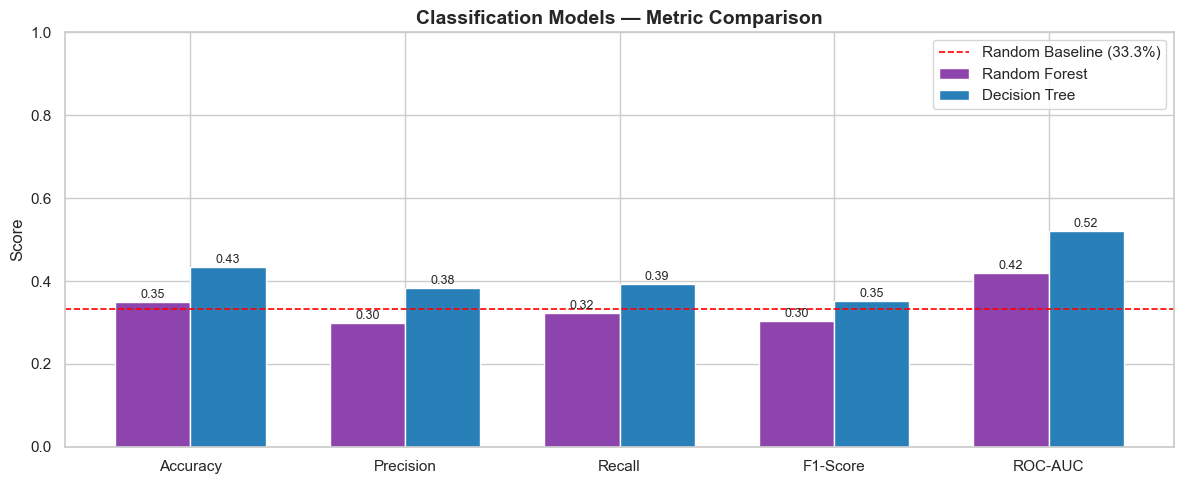

In [201]:
# Visual comparison chart for classification models
metrics_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'],
    'Random Forest': [rfc_acc, rfc_prec, rfc_rec, rfc_f1, rfc_auc],
    'Decision Tree': [dt_acc, dt_prec, dt_rec, dt_f1, dt_auc],
})

x = np.arange(len(metrics_df['Metric']))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 5))
bars1 = ax.bar(x - width/2, metrics_df['Random Forest'], width, label='Random Forest', color='#8E44AD', edgecolor='white')
bars2 = ax.bar(x + width/2, metrics_df['Decision Tree'],  width, label='Decision Tree',  color='#2980B9', edgecolor='white')

ax.set_xticks(x)
ax.set_xticklabels(metrics_df['Metric'])
ax.set_ylim(0, 1)
ax.axhline(0.3333, color='red', linestyle='--', linewidth=1.2, label='Random Baseline (33.3%)')
ax.set_title('Classification Models — Metric Comparison', fontsize=14, fontweight='bold')
ax.set_ylabel('Score')
ax.legend()

for bar in list(bars1) + list(bars2):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{bar.get_height():.2f}', ha='center', fontsize=9)

plt.tight_layout()
plt.show()

In [202]:
# Prediction Demo 
sample_input = {
    'Average_Daily_Traffic_Counts':       35000,   # vehicles/day
    'Peak_Hourly_Traffic_Volume':          3500,   # vehicles in peak hour
    'Percentage_of_Commercial_Vehicles':   20.0,   # %
    'Number_of_Road_Accidents':             400,   # count
    'Air_Quality_Index':                    110,   # AQI value
    'Population_Million':                   8.5,   # million
    'Year':                                2023, 
     'City_Encoded':                          5
}

sample_df = pd.DataFrame([sample_input])

# Predict congestion level
pred_class  = rfc_model.predict(sample_df)[0]
pred_label  = le.inverse_transform([pred_class])[0]
pred_proba  = rfc_model.predict_proba(sample_df)[0]

# Predict speed (scale first)
sample_scaled = scaler.transform(sample_df)
pred_speed  = lr_model.predict(sample_scaled)[0]

print('🔍 INPUT VALUES:')
for k, v in sample_input.items():
    print(f'   {k}: {v}')

print(f'\n🚦 PREDICTED CONGESTION LEVEL : {pred_label}')
print(f'🚗 PREDICTED AVG SPEED (LR)   : {pred_speed:.2f} km/h')

print('\n📊 Class Probabilities (RF Classifier):')
for cls, prob in zip(class_names, pred_proba):
    bar = '█' * int(prob * 30)
    print(f'   {cls:8s}: {bar} {prob*100:.1f}%')

🔍 INPUT VALUES:
   Average_Daily_Traffic_Counts: 35000
   Peak_Hourly_Traffic_Volume: 3500
   Percentage_of_Commercial_Vehicles: 20.0
   Number_of_Road_Accidents: 400
   Air_Quality_Index: 110
   Population_Million: 8.5
   Year: 2023
   City_Encoded: 5

🚦 PREDICTED CONGESTION LEVEL : Low
🚗 PREDICTED AVG SPEED (LR)   : 48.11 km/h

📊 Class Probabilities (RF Classifier):
   High    : █████ 19.7%
   Low     : ███████████████ 53.2%
   Medium  : ████████ 27.1%


In [203]:
#Key Insights & Conclusion
print('=' * 65)
print('               PROJECT SUMMARY & KEY FINDINGS')
print('=' * 65)

print('''
📌 DATASET:
   • 300 records across 30 cities and 10 years (2015–2024)
   • No missing values — clean dataset
   • 7 features used for modeling (including Year)

📌 CONGESTION LEVEL DISTRIBUTION:
   • High   (speed < 35 km/h)  : ~25% of records
   • Medium (35–60 km/h)       : ~40% of records
   • Low    (speed > 60 km/h)  : ~35% of records

📌 KEY EDA FINDINGS:
   • Road accidents negatively correlate with average speed
   • Higher population → higher traffic volume + lower speed
   • Higher traffic volume → worse air quality (higher AQI)
   • Commercial vehicles reduce average speed
   • Traffic volume dipped around 2020 (COVID-19 lockdown)

📌 REGRESSION RESULTS:
   • Both regression models show low R² — the dataset features
     are weakly correlated with speed (synthetic data limitation)
   • Random Forest Regressor slightly outperforms Linear Regression

📌 CLASSIFICATION RESULTS:
   • Random Forest Classifier outperforms Decision Tree
   • Both models beat random chance baseline (33.33%)
   • Cross-validation confirms consistent performance
''')
print('=' * 65)

               PROJECT SUMMARY & KEY FINDINGS

📌 DATASET:
   • 300 records across 30 cities and 10 years (2015–2024)
   • No missing values — clean dataset
   • 7 features used for modeling (including Year)

📌 CONGESTION LEVEL DISTRIBUTION:
   • High   (speed < 35 km/h)  : ~25% of records
   • Medium (35–60 km/h)       : ~40% of records
   • Low    (speed > 60 km/h)  : ~35% of records

📌 KEY EDA FINDINGS:
   • Road accidents negatively correlate with average speed
   • Higher population → higher traffic volume + lower speed
   • Higher traffic volume → worse air quality (higher AQI)
   • Commercial vehicles reduce average speed
   • Traffic volume dipped around 2020 (COVID-19 lockdown)

📌 REGRESSION RESULTS:
   • Both regression models show low R² — the dataset features
     are weakly correlated with speed (synthetic data limitation)
   • Random Forest Regressor slightly outperforms Linear Regression

📌 CLASSIFICATION RESULTS:
   • Random Forest Classifier outperforms Decision Tree
  